In [42]:
import pandas as pd, numpy as np, math
# import pyg_lib
from scipy import stats as scipy_stats
from typing import Union, List, Tuple, Callable
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import MessagePassing, GINConv
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected, remove_self_loops, subgraph as pyg_subgraph
from torch_geometric.loader import NeighborLoader
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

device: cuda


In [2]:
def bin_target(df: pd.DataFrame, target_col: str) -> dict:
    """
    Discretise a target column using Scott's rule and return a mapping
    of bin_id -> list of row indices.

    Scott's rule:
        bin_width  h = 3.5 * std(x) * n^(-1/3)
        n_bins       = ceil((max(x) - min(x)) / h)
    """
    x = df[target_col].dropna().values
    n = len(x)

    if n < 2:
        raise ValueError("Need at least 2 non-null values to compute bins.")

    std = np.std(x, ddof=1)          # sample standard deviation
    if std == 0:
        raise ValueError("Target column has zero variance; cannot bin.")

    h       = 3.5 * std * (n ** (-1 / 3))          # Scott's bin width
    n_bins  = max(1, math.ceil((x.max() - x.min()) / h))

    bin_series = pd.cut(
        df[target_col],
        bins=n_bins,
        labels=range(n_bins),
        include_lowest=True
    )

    bin_dict = {}
    for bin_id, group in df.groupby(bin_series, observed=True):
        bin_dict[int(bin_id)] = list(group.index)

    return bin_dict, n_bins

In [3]:
DIST_MAP = {
    "normal":      scipy_stats.norm,
    "gaussian":    scipy_stats.norm,
    "exponential": scipy_stats.expon,
    "beta":        scipy_stats.beta,
    "gamma":       scipy_stats.gamma,
    "uniform":     scipy_stats.uniform,
    "lognormal":   scipy_stats.lognorm,
}

def make_pdf(
    spec: Union[
        Tuple[str, dict],
        List[Tuple[str, dict, float]]
    ]
) -> Callable:
    """
    Single distribution:
        spec = ("normal", {"loc": 0, "scale": 1})

    Mixture (weights are auto-normalised):
        spec = [
            ("normal",      {"loc": 0, "scale": 1},  0.6),
            ("exponential", {"scale": 2},             0.4),
        ]
    """
    if isinstance(spec, tuple):
        name, params = spec
        dist = DIST_MAP[name.lower()]
        return lambda x: dist.pdf(x, **params)

    total_w    = sum(w for _, _, w in spec)
    components = [(DIST_MAP[n.lower()], p, w / total_w) for n, p, w in spec]

    def mixture_pdf(x):
        return sum(w * d.pdf(x, **p) for d, p, w in components)

    return mixture_pdf


def _bin_centers(df: pd.DataFrame, target_col: str, n_bins: int) -> np.ndarray:
    """Midpoint of each equal-width bin over the target column range."""
    lo, hi = df[target_col].min(), df[target_col].max()
    edges  = np.linspace(lo, hi, n_bins + 1)
    return (edges[:-1] + edges[1:]) / 2

In [4]:
def knn_descriptors(pos: torch.Tensor, k: int):
    """kNN indices over descriptor coords using L1 distance.  Returns (N, k).

    Uses KeOps on GPU; falls back to a torch.cdist L1 computation on CPU so
    the model runs without CUDA (same L1 metric as the original).
    """
    N, D = pos.shape
    if pos.is_cuda:
        from pykeops.torch import LazyTensor
        x_i = LazyTensor(pos.view(N, 1, D))
        y_j = LazyTensor(pos.view(1, N, D))
        return (x_i - y_j).abs().sum(dim=-1).argKmin(K=k, dim=1)
    return torch.cdist(pos, pos, p=1).topk(k, largest=False).indices

In [14]:
def make_mlp(*dims):
    """Linear -> ReLU -> ... -> Linear (no activation on last layer)."""
    layers = []
    for i in range(len(dims) - 1):
        layers.append(nn.Linear(dims[i], dims[i + 1]))
        if i < len(dims) - 2:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)


class EdgeGatedGIN(MessagePassing):
    """
    Single GIN layer where each message x_j is scaled by the
    0/1 label of the edge j->i. Self-features start from original input.
    """
    def __init__(self, in_channels, out_channels, hidden):
        super().__init__(aggr='mean')
        self.eps = nn.Parameter(torch.zeros(1))
        self.mlp = make_mlp(in_channels, hidden, out_channels)

    def forward(self, x, edge_index, edge_label):
        agg = self.propagate(edge_index, x=x, edge_label=edge_label)
        return self.mlp((1 + self.eps) * x + agg)

    def message(self, x_j, edge_label):
        return x_j * edge_label   # (E, in_channels) * (E, 1)

In [15]:
class KNNBreathe(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_gin_layers, num_iter_layers):
        super().__init__()
        self.num_iter_layers = num_iter_layers

        # --- Stage 1: initial GIN layers ---
        self.gin_layers = nn.ModuleList(
            [GINConv(make_mlp(in_channels, hidden_channels, hidden_channels), train_eps=True)]
        )
        for _ in range(num_gin_layers - 1):
            self.gin_layers.append(
                GINConv(make_mlp(hidden_channels, hidden_channels, hidden_channels), train_eps=True)
            )
        self.node_head_0 = make_mlp(hidden_channels, hidden_channels, 2)   # 2 logits

        # --- Iterative components ---
        self.edge_mlps = nn.ModuleList([
            make_mlp(2 * hidden_channels, hidden_channels, 1)
            for _ in range(num_iter_layers)
        ])
        self.edge_gin_layers = nn.ModuleList([
            EdgeGatedGIN(hidden_channels, hidden_channels, hidden_channels)
            for _ in range(num_iter_layers)
        ])
        self.node_heads = nn.ModuleList([
            make_mlp(hidden_channels, hidden_channels, 2)                  # 2 logits
            for _ in range(num_iter_layers)
        ])

    def forward(self, x, edge_index, tau=1.0):
        """
        x          : (N, in_channels)
        edge_index : (2, E)
        tau        : Gumbel-Softmax temperature (annealed during training)
        """
        row, col = edge_index
        node_logits_list = []
        edge_logits_list = []

        # --- Stage 1: initial GIN ---
        h = x
        for gin in self.gin_layers:
            h = F.relu(gin(h, edge_index))
        node_logits = self.node_head_0(h)                                        # (N, 2)
        node_logits_list.append(node_logits)
        node_labels = F.gumbel_softmax(node_logits, tau=tau, hard=False)[:, 1:]  # (N, 1)

        # --- Iterative components ---
        for i in range(self.num_iter_layers):
            nl_u = node_labels[row]
            nl_v = node_labels[col]
            xor_gate  = nl_u + nl_v - 2 * nl_u * nl_v
            edge_feat = torch.cat([h[row], h[col]], dim=-1) * xor_gate

            edge_logits = self.edge_mlps[i](edge_feat)
            edge_logits_list.append(edge_logits)
            edge_labels = torch.sigmoid(edge_logits)

            h = F.relu(self.edge_gin_layers[i](h, edge_index, edge_labels))

            node_logits = self.node_heads[i](h)                                       # (N, 2)
            node_logits_list.append(node_logits)
            node_labels = F.gumbel_softmax(node_logits, tau=tau, hard=False)[:, 1:]   # (N, 1)

        return node_logits_list, edge_logits_list

In [156]:
LN_2 = torch.log(torch.tensor(2))

def distribution_match_loss(membership, node_hists, target_dist, gamma=0.5, lam=0.0, eps=1e-9):
    subgroup_hist = (membership.unsqueeze(1) * node_hists).sum(0) + eps
    subgroup_size = membership.sum() + eps

    P = subgroup_hist / subgroup_hist.sum()
    Q = (target_dist + eps) / (target_dist + eps).sum()

    M   = 0.5 * (P + Q)
    jsd = 0.5 * (P * torch.log(P / M)).sum() + 0.5 * (Q * torch.log(Q / M)).sum()

    # kld = (P * torch.log(P / Q)).sum()

    # size_frac = subgroup_size / membership.numel()

    weighted_jsd = 1.0 / (jsd * (subgroup_size ** gamma))
    reg = lam * (membership * torch.log(membership + eps)).mean()
    loss        = -weighted_jsd + reg #- gamma * size_frac
    
    return loss, jsd.item(), subgroup_size.item()

In [118]:
def build_pyg_graph(feats, knn_geo):
    """
    feats   : (N, d)  node feature tensor
    knn_geo : (N, k)  each row lists k neighbor indices for that node
    """
    N, k = knn_geo.shape
    src = torch.arange(N, device=feats.device).unsqueeze(1).expand(N, k).reshape(-1)
    dst = knn_geo.reshape(-1)
    edge_index = torch.stack([src, dst], dim=0)            # (2, N*k)
    edge_index, _ = remove_self_loops(edge_index)
    edge_index = to_undirected(edge_index, num_nodes=N)    # adds reverse edges + dedupes
    return Data(x=feats, edge_index=edge_index)

In [164]:
np.random.seed(42)
df = pd.DataFrame({
    "feature_a": np.random.randn(1500),
    "feature_b": np.random.randn(1500),
    "feature_c": np.random.randn(1500),
    "target":    np.random.rand(1500),
})
target_col = "target"
desc_cols  = [c for c in df.columns if c != target_col]
N          = len(df)

_, n_bins = bin_target(df, target_col)            # Scott's rule

# node histograms: one-hot of which target bin each row falls in
bin_ids = pd.cut(df[target_col], bins=n_bins, labels=range(n_bins),
                 include_lowest=True).astype(int).to_numpy()
hists = torch.zeros((N, n_bins), device=device)
hists[torch.arange(N), torch.tensor(bin_ids, device=device)] = 1.0

# THE GIVEN DISTRIBUTION: specified pdf at bin centres, normalised over bins
pdf         = make_pdf(("gaussian", {"loc": 0.5, "scale": 0.15}))
centers     = _bin_centers(df, target_col, n_bins)
target_dist = torch.tensor([pdf(c) for c in centers], dtype=torch.float32, device=device)
target_dist = target_dist / target_dist.sum()

# kNN graph on DESCRIPTORS only; node features = descriptors + target histogram
pos     = torch.tensor(df[desc_cols].to_numpy(), dtype=torch.float32, device=device)
knn_geo = knn_descriptors(pos, k=math.floor(math.sqrt(N)))
feats   = torch.cat([pos, hists], dim=1).to(torch.float32)
print(f"n_bins={n_bins}  feats={tuple(feats.shape)}  knn={tuple(knn_geo.shape)}")

[pyKeOps] Warning : at least one of the input tensors is not contiguous. Consider using contiguous data arrays to avoid unnecessary copies.
n_bins=12  feats=(1500, 15)  knn=(1500, 38)


In [165]:
# Model
in_channels           = feats.shape[1]
hidden_channels       = 256
num_gin_layers        = 2
num_iter_layers       = 3

# Training
lr                    = 1e-4
num_epochs            = 250
gamma                 = 0.1     # size reward weight (required)
lam                   = 1.0     # membership entropy reg
membership_threshold  = 0.1
batch_size            = 512
num_neighbors_per_hop = int(math.sqrt(N) // 2)

# Gumbel-Softmax temperature annealing
tau_start             = 1.0
tau_min               = 0.001
anneal_rate           = 0.01    # tau = max(tau_min, tau_start * exp(-anneal_rate * epoch))

In [166]:
data         = build_pyg_graph(feats, knn_geo).to(device)
num_hops     = num_gin_layers + num_iter_layers
results      = []

train_loader = NeighborLoader(
    data, num_neighbors=[num_neighbors_per_hop] * num_hops,
    batch_size=batch_size, shuffle=True,
)
inference_loader = NeighborLoader(
    data, num_neighbors=[num_neighbors_per_hop] * num_hops,
    batch_size=batch_size, shuffle=False,
)

model = KNNBreathe(
    in_channels=in_channels,
    hidden_channels=hidden_channels,
    num_gin_layers=num_gin_layers,
    num_iter_layers=num_iter_layers,
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [167]:
for epoch in range(num_epochs):
    tau = max(tau_min, tau_start * math.exp(-anneal_rate * epoch))
    model.train()
    epoch_loss = 0.0

    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        node_logits_list, _ = model(batch.x, batch.edge_index, tau=tau)
        membership = F.gumbel_softmax(
            node_logits_list[-1], tau=tau, hard=False
        )[:, 1]                                          # (N_batch,)

        batch_hists = hists[batch.n_id]
        loss, jsd, size = distribution_match_loss(
            membership, batch_hists, target_dist, gamma=gamma, lam=lam,
        )
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print(
        f"epoch {epoch + 1}/{num_epochs}  tau={tau:.3f}  "
        f"avg_loss={epoch_loss / len(train_loader):.4f}  jsd={jsd:.4f}  size={size:.1f}"
    )

epoch 1/250  tau=1.000  avg_loss=-3.8914  jsd=0.1413  size=736.7
epoch 2/250  tau=0.990  avg_loss=-3.9918  jsd=0.1367  size=687.9
epoch 3/250  tau=0.980  avg_loss=-4.0202  jsd=0.1425  size=650.5
epoch 4/250  tau=0.970  avg_loss=-4.0058  jsd=0.1380  size=567.7
epoch 5/250  tau=0.961  avg_loss=-4.2215  jsd=0.1289  size=407.8
epoch 6/250  tau=0.951  avg_loss=-4.2247  jsd=0.1575  size=160.9
epoch 7/250  tau=0.942  avg_loss=-4.8254  jsd=0.1434  size=61.4
epoch 8/250  tau=0.932  avg_loss=-5.4645  jsd=0.1488  size=15.2
epoch 9/250  tau=0.923  avg_loss=-5.6014  jsd=0.1340  size=8.4
epoch 10/250  tau=0.914  avg_loss=-6.1285  jsd=0.1337  size=15.6
epoch 11/250  tau=0.905  avg_loss=-5.5133  jsd=0.1742  size=12.1
epoch 12/250  tau=0.896  avg_loss=-6.2938  jsd=0.1606  size=6.5
epoch 13/250  tau=0.887  avg_loss=-7.8023  jsd=0.1740  size=2.0
epoch 14/250  tau=0.878  avg_loss=-4.9579  jsd=0.2073  size=1.2
epoch 15/250  tau=0.869  avg_loss=-5.6165  jsd=0.2023  size=2.3
epoch 16/250  tau=0.861  avg_loss

In [146]:
# Batched inference — deterministic softmax, no Gumbel noise
model.eval()
membership_all = torch.zeros(data.num_nodes, device=device)

with torch.no_grad():
    for batch in inference_loader:
        batch = batch.to(device)
        node_logits_list, _ = model(batch.x, batch.edge_index, tau=tau_min)
        seed_membership = F.softmax(
            node_logits_list[-1][:batch.batch_size], dim=-1
        )[:, 1]
        membership_all[batch.n_id[:batch.batch_size]] = seed_membership

subgroup_hist  = (membership_all.unsqueeze(1) * hists).sum(0).detach()
subgroup_nodes = (membership_all >= membership_threshold).nonzero(as_tuple=True)[0]

results.append({
    'membership':     membership_all.cpu(),
    'subgroup_nodes': subgroup_nodes.cpu(),
    'subgroup_hist':  subgroup_hist.cpu(),
})
print(f"{subgroup_nodes.numel()} nodes selected")

130 nodes selected


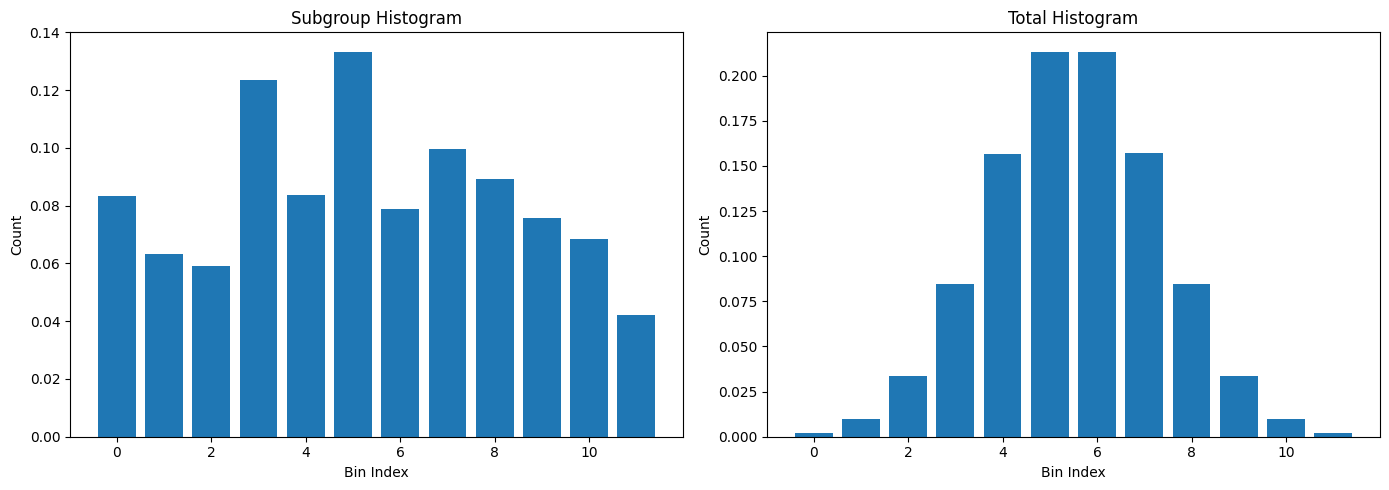

In [147]:
# Ensure the tensors are on CPU and converted to numpy for plotting
subgroup_hist_np = subgroup_hist.cpu().numpy()
subgroup_dist_np = subgroup_hist_np / subgroup_hist_np.sum()
total_dist_np = target_dist.cpu().numpy()

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot subgroup_hist
axes[0].bar(range(len(subgroup_dist_np)), subgroup_dist_np)
axes[0].set_title('Subgroup Histogram')
axes[0].set_xlabel('Bin Index')
axes[0].set_ylabel('Count')

# Plot total_hist
axes[1].bar(range(len(total_dist_np)), total_dist_np)
axes[1].set_title('Total Histogram')
axes[1].set_xlabel('Bin Index')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [35]:
def count_induced_components(subgroup_nodes, edge_index, num_nodes):
    """
    subgroup_nodes : (M,) tensor of selected node indices
    edge_index     : (2, E) full graph edge index
    num_nodes      : total number of nodes in the full graph
    """
    n = subgroup_nodes.size(0)
    if n == 0:
        return 0

    sub_edge_index, _ = pyg_subgraph(
        subgroup_nodes, edge_index,
        relabel_nodes=True, num_nodes=num_nodes,
    )

    if sub_edge_index.size(1) == 0:
        return n   # all nodes are isolated

    row = sub_edge_index[0].cpu().numpy()
    col = sub_edge_index[1].cpu().numpy()
    adj = csr_matrix((np.ones(len(row)), (row, col)), shape=(n, n))
    n_components, _ = connected_components(adj, directed=False, connection='weak')
    return n_components


for sg_idx, result in enumerate(results):
    n_comp = count_induced_components(
        result['subgroup_nodes'],
        data.edge_index.cpu(),
        data.num_nodes,
    )
    print(f"Subgroup {sg_idx + 1}: {result['subgroup_nodes'].numel()} nodes, "
          f"{n_comp} connected component(s)")

Subgroup 1: 1500 nodes, 1 connected component(s)
